# Validate against buoy observations

Compare the **offshore hindcast** (closest goal node) and the **spectral
metamodel** of each offshore source, with and without the wind correction (water
level from `forcing.water_level`), to buoy records. The dynamic runs are
compared in `09_Validate_Linear_Summation.ipynb`.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Offshore sources (`07a`, `07b`) and the wind correction (`05b`)
3. Observations GeoJSON — `03_Generate_Observations_Configuration.ipynb` → `inputs/Observations/<Case>_observations.json`
4. Processed hourly buoy files in `inputs/Observations/processed/` (notebook 03,
   `utils/buoy_archive.py`).

The reconstructions are read from the cache (`tmp/reconstruct/`); fill it
beforehand with `python reconstruct_buoys.py` (same period and setups, on the
compute node). Anything missing is computed here.

Comparisons request **`hs`, `tp`, `dir`, and `spr`**. Variables missing from the buoy
file or any model are skipped automatically.

The buoys validated are
the `ok` buoy sites of `outputs/output_sites_{model}.csv` (notebook 03) that have
`hs` in `period`; buoys outside the mesh or that can dry have no model output.

In [1]:
import matplotlib.pyplot as plt
from utils import metamodel as mm
from utils import onshore_sites as obs
from utils import validation as val

## Configuration

The modelled buoys of the observations GeoJSON (`instrument_id` keys that are `ok`
output sites, notebook 03). Site labels are `buoy_{instrument_id}`. Processed hourly files (`hs`, `tp`, `dir`,
`spr` where measured) come from `utils/buoy_archive.py` (Waterinfo + CMEMS + the
earlier Rijkswaterstaat exports), built in notebook 03.

In [2]:
period = slice("1979-01-01", "2018-12-31")  # CODEC water level ends in 2018
offshore_names = ["WHACS_cal", "ERA5_cal"]  # offshore_waves entries
wind_corrections = [False, True]
mda_n = 550  # must match a fitted mda_candidates entry
mm_set = "buoys"  # metamodel set (metamodel.sets) fitted on the buoys
primary = "Metamodel WHACS_cal · wind off"  # estimate of the GUI summary figures

# Modelled buoys (ok output sites, notebook 03); processed hourly files
# (hs, tp, dir, spr) in inputs/Observations/processed/<instrument_id>.nc
sites = obs.list_snapwave_buoy_sites()

requested_variables = ["hs", "tp", "dir", "spr"]

print("Observations JSON:", obs.geojson_path())
print(f"period         : {period}")
print(f"offshore       : {offshore_names}, wind correction {wind_corrections}")
print(f"mda_n          : {mda_n}")
print(f"metamodel      : {mm_set}")
print(f"sites          : {sites}")
print(f"requested vars : {requested_variables}")

Observations JSON: /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json
period         : slice('1979-01-01', '2018-12-31', None)
offshore       : ['WHACS_cal', 'ERA5_cal'], wind correction [False, True]
mda_n          : 550
metamodel      : buoys
sites          : ['buoy_A2', 'buoy_AWG', 'buoy_Akkaert', 'buoy_Amelander31', 'buoy_AmelanderZeegat_1_1', 'buoy_BolVanHeistBuoy', 'buoy_Brouwershavensegat', 'buoy_CadzandBoei', 'buoy_Deurlo', 'buoy_DomburgerRassen', 'buoy_EierlandseGat', 'buoy_EurogeulDWE', 'buoy_EurogeulE13', 'buoy_EurogeulE5', 'buoy_Europlatform', 'buoy_GoereeLichteiland', 'buoy_IJgeul', 'buoy_IJgeulStroommeetpaal', 'buoy_IJmuidenMunitiestort_1', 'buoy_KwintebankBuoy', 'buoy_L91', 'buoy_MeetboeiWEO1', 'buoy_OostendNorth', 'buoy_Oosterschelde11', 'buoy_OstendEasternPalisadeBuoy', 'buoy_OstendPoortjesBuoy', 'buoy_PettenMeetraai01', 'buoy_Q1', 'buoy_Raversijde2', 'buoy_ScheurWest', 'buoy_SchiermonnikoogNoord', 'buoy_Sch

## 1 · Check models

In [3]:
mm.require_models(mm_set, mda_n)

## 2 · Buoy observations

The processed hourly file of each buoy (notebook 03) in `period`, on
`(time, sites)` with CF-style attributes and the site metadata; buoys without
`hs` in `period` are skipped.

In [4]:
buoy = val.load_buoy_observations(period, sites, variables=requested_variables)
skipped = sorted(set(sites) - set(buoy.sites.values))
sites = list(buoy.sites.values)
print(f"{len(sites)} buoys with hs in {period}; skipped (no data): {skipped}")
buoy

32 buoys with hs in slice('1979-01-01', '2018-12-31', None); skipped (no data): ['buoy_A2', 'buoy_OostendNorth', 'buoy_OstendEasternPalisadeBuoy', 'buoy_OstendPoortjesBuoy', 'buoy_Raversijde2', 'buoy_ThorntonbankSouthBuoy']


<xarray.Dataset> Size: 337MB
Dimensions:             (time: 326411, sites: 32)
Coordinates:
  * time                (time) datetime64[ns] 3MB 1979-01-01 ... 2018-12-31T2...
  * sites               (sites) <U27 3kB 'buoy_AWG' ... 'buoy_zdv8-2d-MMND'
    site_source         (sites) object 256B 'buoy' 'buoy' ... 'buoy' 'buoy'
    site_label          (sites) object 256B 'waves' 'waves' ... 'waves' 'waves'
    site_mesh_depth     (sites) float64 256B 9.97 22.64 14.97 ... 13.55 16.03
    site_nominal_depth  (sites) float64 256B 11.0 22.0 13.0 ... 15.0 8.0 21.0
    site_longitude      (sites) float64 256B 5.95 2.82 5.6 ... 6.367 3.42 4.01
    site_latitude       (sites) float64 256B 53.5 51.42 53.45 ... 51.43 51.99
Data variables:
    hs                  (time, sites) float64 84MB nan nan nan ... 0.475 nan
    tp                  (time, sites) float64 84MB nan nan nan ... 3.852 nan
    dir                 (time, sites) float64 84MB nan nan nan ... 291.4 nan nan
    spr                 (time, sites) float64 84MB nan nan nan ... 34.6 nan nan

## 3 · Metamodel reconstructions and closest-goal offshore hindcast

The spectral metamodel for every offshore source x wind correction (read from
the cache), and the bulk offshore hindcast at each buoy's **closest goal node**.

In [5]:
# Resources for the reconstructions below (at most 75% of this machine); the
# wind-on request is the larger one. Edit res if wanted (res.workers = ...).
res = mm.reconstruction_resources(
    period,
    mda_n,
    metamodel=mm_set,
    spectral=True,
    offshore_name=offshore_names[0],
    wl="forcing",
    save_spectra=False,
    wind_correction=True,
)

Machine   48 cores, 434 GiB free of 503 GiB, no GPU -> at most 36 cores, 325 GiB (75%)
Request   buoys n=550 spectral (41 contributions/site), slice('1979-01-01', '2018-12-31', None): 0 of 18240 site-months to compute, in 0 month(s)
Proposed  device cpu, 36 threads (GP + PCA), 36 workers (spectral sum), 1 month(s) x every site per call, 325 GiB
Spectra   not saved (save_spectra=True to keep them): ~0.0 GB on disk for these site-months, 16564 GB free
Edit the fields if wanted (res.workers = ...), then reconstruct(..., resources=res).


In [6]:
metamodel = {
    f"Metamodel {name} · wind {'on' if wind else 'off'}": mm.reconstruct(
        period,
        mda_n,
        metamodel=mm_set,
        spectral=True,
        offshore_name=name,
        wl="forcing",
        save_spectra=False,
        wind_correction=wind,
        resources=res,
    )
    for name in offshore_names
    for wind in wind_corrections
}

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    offshore_names=offshore_names,
    variables=requested_variables,
)

estimates = {**offshore_hindcast, **metamodel}

variables = val.resolve_comparison_variables(
    buoy,
    *estimates.values(),
    variables=requested_variables,
)
print(f"Comparing: {variables}")

Comparing: ['hs', 'tp', 'dir', 'spr']


## 4 · Metrics vs buoy

In [7]:
results = val.compare_all(
    buoy,
    estimates,
    variables=variables,
    reference_label="Buoy",
)

summary = val.metrics_summary(results)
summary

,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,model
0,buoy_AWG,buoy,waves,hs,Hs,35370,0.697554,0.892933,1.096251,0.552129,0.830161,-1.240371,WHACS_cal (closest goal)
1,buoy_AWG,buoy,waves,tp,Tp,37144,-2.176321,4.075637,0.443521,0.344524,0.505337,-0.064981,WHACS_cal (closest goal)
2,buoy_AWG,buoy,waves,dir,Dir,0,NaN,NaN,NaN,NaN,NaN,NaN,WHACS_cal (closest goal)
3,buoy_AWG,buoy,waves,spr,Spr,0,NaN,NaN,NaN,NaN,NaN,NaN,WHACS_cal (closest goal)
4,buoy_Akkaert,buoy,waves,hs,Hs,22029,0.068497,0.230130,0.237191,0.193077,0.945353,0.850155,WHACS_cal (closest goal)
...,...,...,...,...,...,...,...,...,...,...,...,...,...
763,buoy_WielingenNoord,buoy,waves,spr,Spr,0,NaN,NaN,NaN,NaN,NaN,NaN,Metamodel ERA5_cal · wind on
764,buoy_zdv8-2d-MMND,buoy,waves,hs,Hs,86499,0.126694,0.353888,0.340161,0.273789,0.883356,0.665351,Metamodel ERA5_cal · wind on
765,buoy_zdv8-2d-MMND,buoy,waves,tp,Tp,54932,3.516369,7.135362,1.232130,1.031076,0.092046,-17.695484,Metamodel ERA5_cal · wind on
766,buoy_zdv8-2d-MMND,buoy,waves,dir,Dir,0,NaN,NaN,NaN,NaN,NaN,NaN,Metamodel ERA5_cal · wind on


Median over the buoys, per estimate and variable:

In [8]:
summary.groupby(["label", "model"])[["n", "bias", "rmse", "r2"]].median().round(3)

n   bias    rmse      r2
label model                                                         
Dir   ERA5_cal (closest goal)         10247.5  1.167  39.332   0.466
      Metamodel ERA5_cal · wind off   10247.5  8.297  41.323   0.481
      Metamodel ERA5_cal · wind on    10247.5  6.717  39.313   0.509
      Metamodel WHACS_cal · wind off  10247.5  9.035  38.923   0.543
      Metamodel WHACS_cal · wind on   10247.5  5.836  33.255   0.659
      WHACS_cal (closest goal)        10247.5  3.045  31.271   0.650
Hs    ERA5_cal (closest goal)         86172.5  0.253   0.443   0.597
      Metamodel ERA5_cal · wind off   86172.5  0.090   0.363   0.714
      Metamodel ERA5_cal · wind on    86172.5  0.177   0.392   0.669
      Metamodel WHACS_cal · wind off  86172.5 -0.002   0.295   0.814
      Metamodel WHACS_cal · wind on   86172.5  0.188   0.326   0.776
      WHACS_cal (closest goal)        86172.5  0.267   0.452   0.561
Spr   ERA5_cal (closest goal)             0.0 -9.012  12.752  -0.872
      Metamodel ERA5_cal · wind off       0.0 -4.439  12.615  -0.599
      Metamodel ERA5_cal · wind on        0.0 -3.748  12.177  -0.445
      Metamodel WHACS_cal · wind off      0.0 -8.160  13.622  -1.463
      Metamodel WHACS_cal · wind on       0.0 -5.800  13.706  -0.806
      WHACS_cal (closest goal)            0.0 -5.102  12.942  -0.377
Tp    ERA5_cal (closest goal)         87739.0 -0.150   1.634   0.213
      Metamodel ERA5_cal · wind off   87739.0  2.936   6.609 -12.165
      Metamodel ERA5_cal · wind on    87739.0  2.354   6.055 -10.052
      Metamodel WHACS_cal · wind off  87735.5  0.960   3.105  -1.543
      Metamodel WHACS_cal · wind on   87735.0  0.528   2.722  -0.835
      WHACS_cal (closest goal)        87739.0  0.518   2.265  -0.383

## 4b · Save summary

In [9]:
# `period` is a slice here (not a single string) — derive a clean,
# filesystem-safe label from it once; the summary PNG save cell reuses it.
period_label = period if isinstance(period, str) else f"{period.start}-{period.stop}"

summary_out = summary.copy()
summary_out.insert(0, "period", period_label)
summary_out.insert(1, "metamodel", mm_set)
summary_out.insert(2, "mda_candidate", mda_n)

out_path = val.buoy_validation_path("onshore", period_label)
out_path.parent.mkdir(parents=True, exist_ok=True)
summary_out.to_csv(out_path, index=False)
print(f"Wrote {out_path}")

Wrote /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/onshore_summary_1979-01-01-2018-12-31.csv


## 5 · Scatter plots

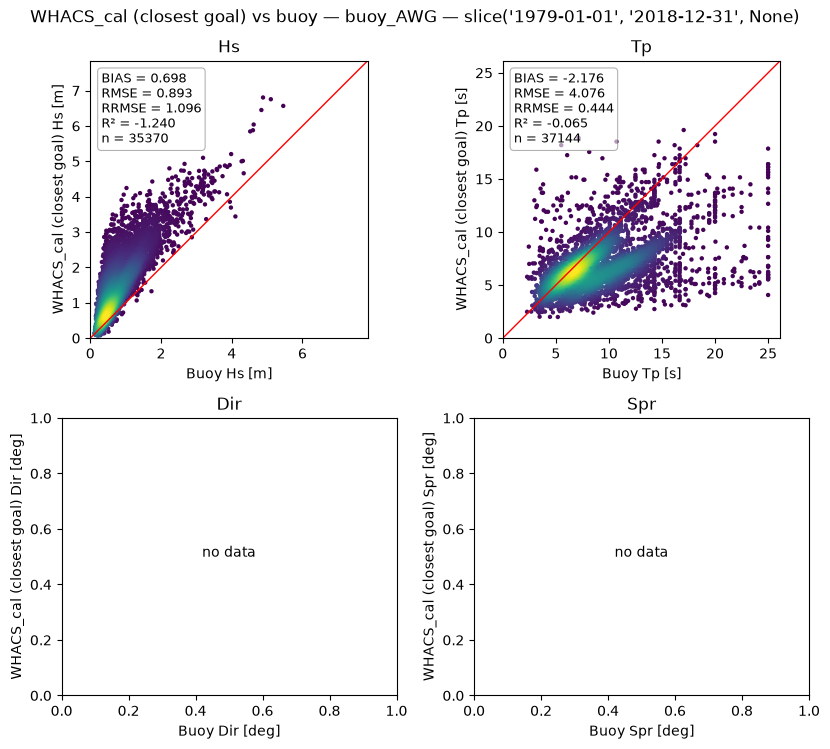

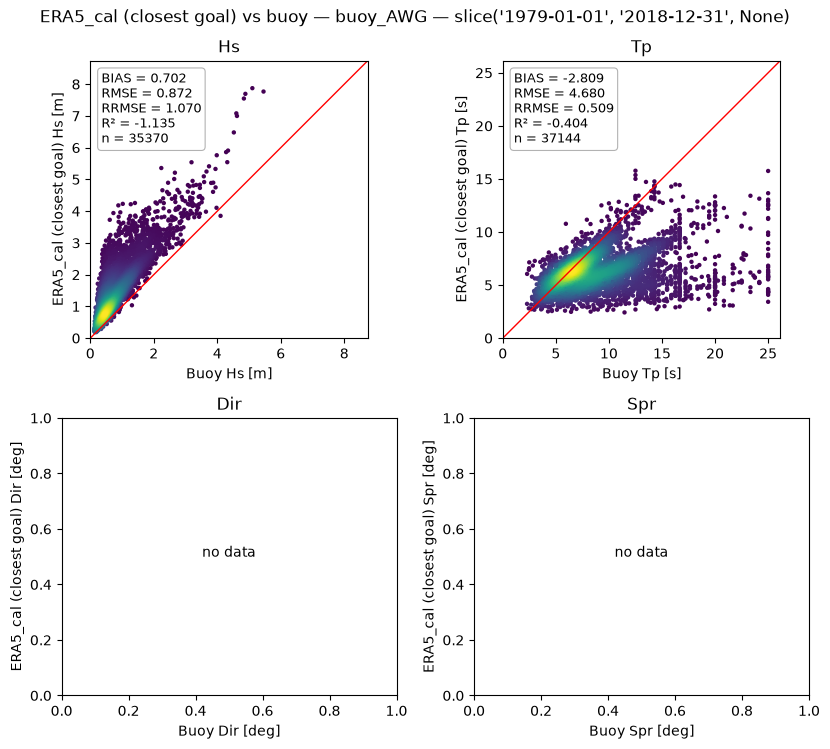

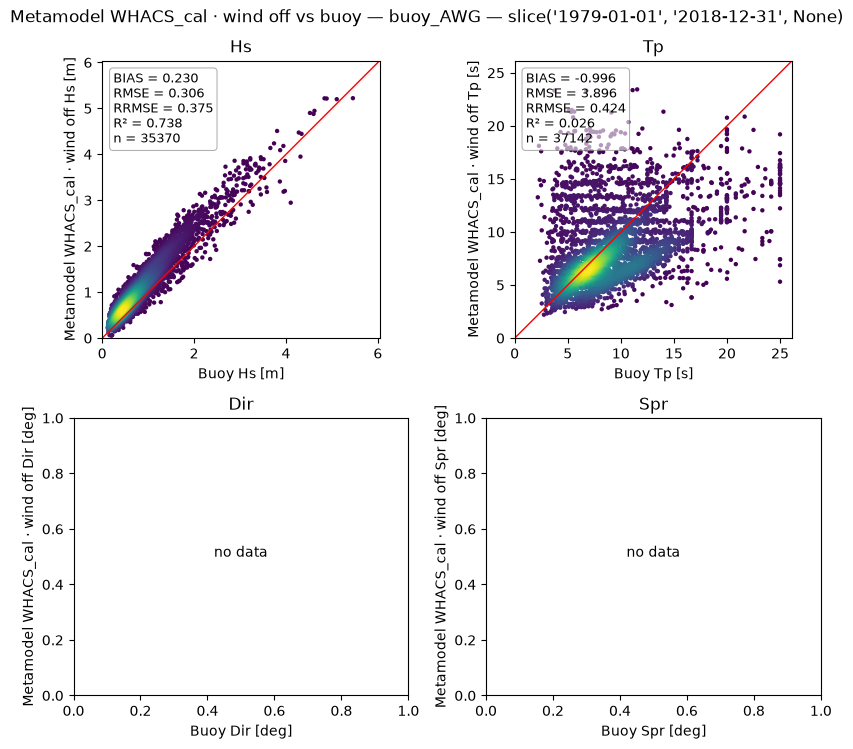

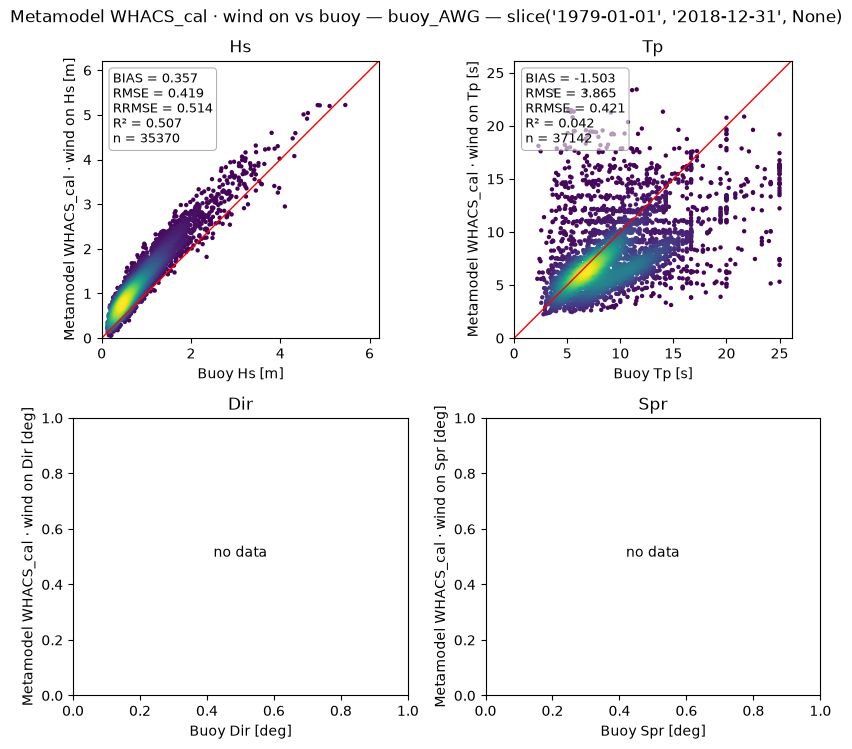

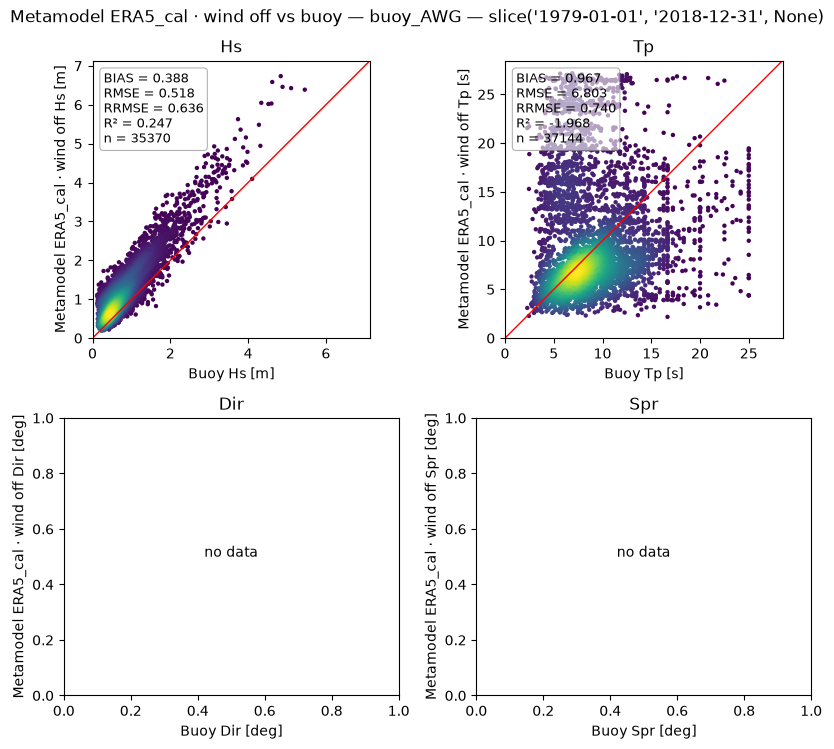

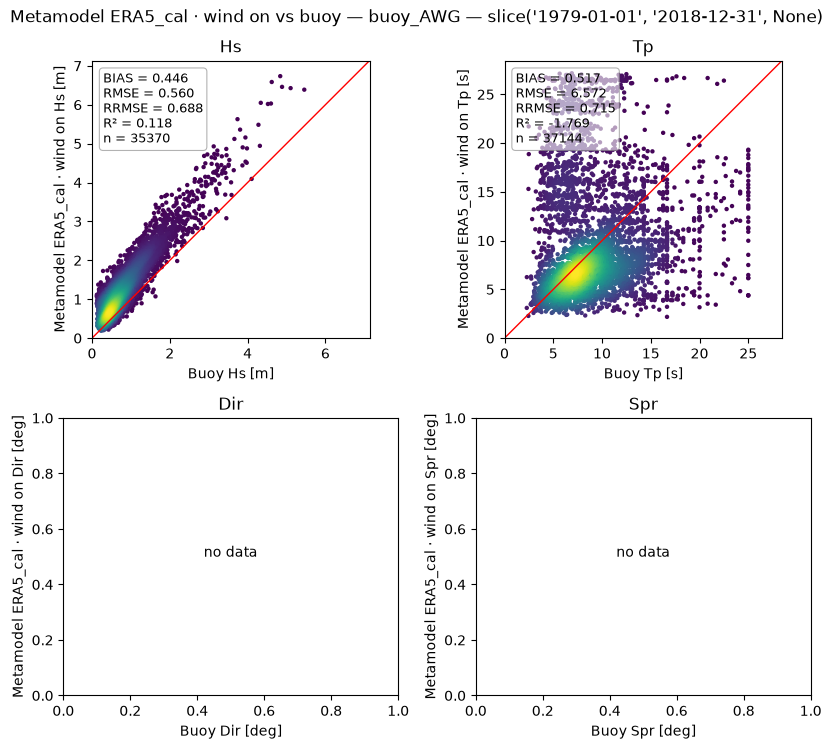

In [10]:
for site in sites:
    for name, result in results.items():
        result.plot_scatter(site, variables)
        plt.suptitle(f"{name} vs buoy — {site} — {period}")
        plt.show()
    break

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

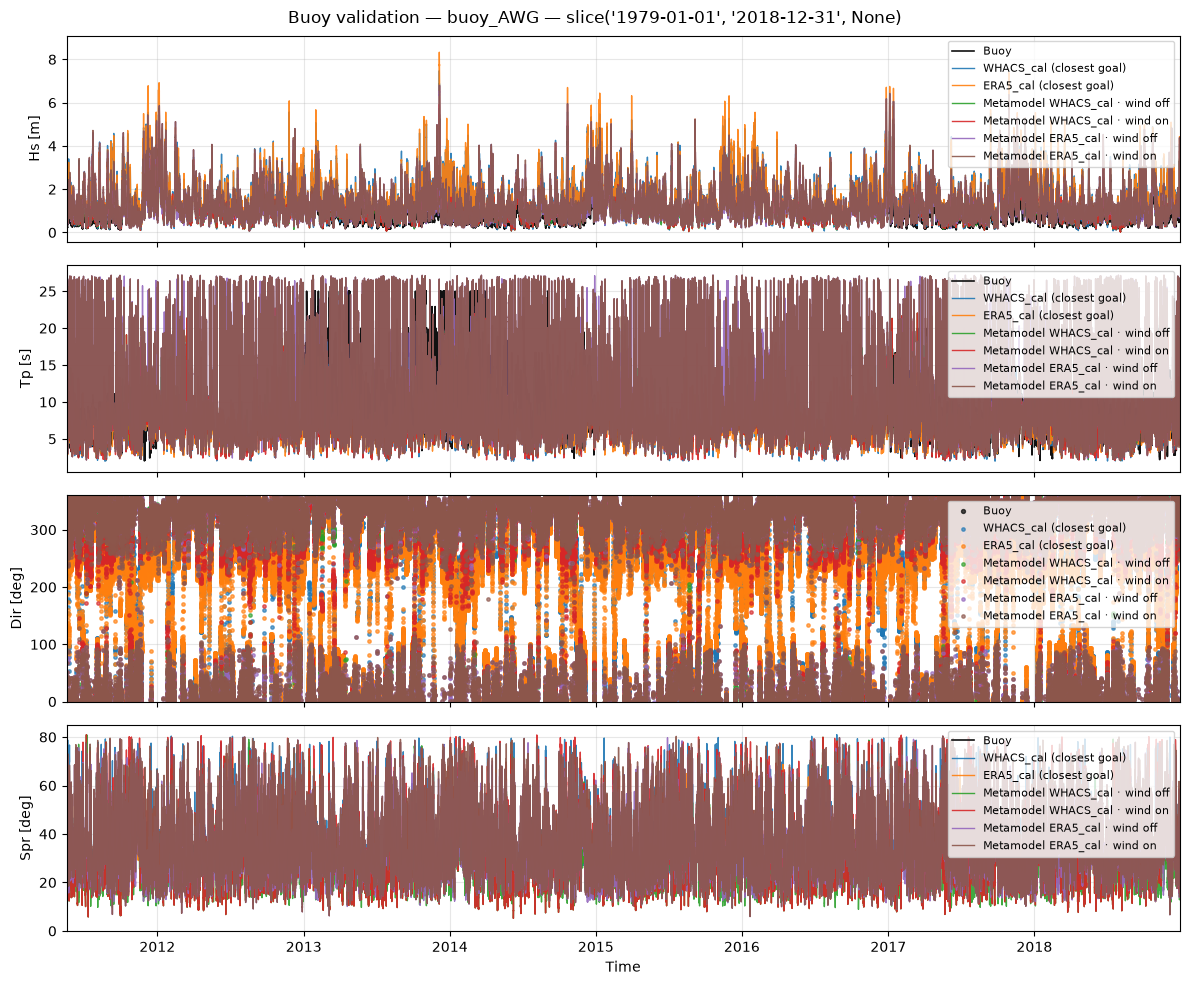

In [11]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()
    break

## 7 · Save per-buoy summary PNG (GUI)

Density scatter (top row, buoy vs. the `primary` estimate) + one wide Hs/Tp time series (bottom row, cropped to when the buoy actually has data) — one combined PNG per buoy, shown as-is in the GUI's Buoy Validation tab when you click that buoy's star on the map.

In [12]:
for site in sites:
    fig = val.plot_buoy_summary(
        buoy,
        estimates[primary],
        site,
        variables=variables,
        reference_label="Buoy",
        period_label=period_label,
        estimate_label=primary,
        cmap="Reds",
    )
    out_path = val.buoy_summary_figure_path(site)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"saved {out_path}")

saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_AWG.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_Akkaert.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_Amelander31.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_AmelanderZeegat_1_1.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_BolVanHeistBuoy.png


...

saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_Schouwenbank.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_StortemelkWest.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_WestereemsWest.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_WielingenNoord.png


saved /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/buoy_validation/figures/buoy_zdv8-2d-MMND.png
